# LatentMoE: route in full width, compute in a small latent space

*Elango et al. (NVIDIA), "LatentMoE: Toward Optimal Accuracy per FLOP and Parameter in Mixture of Experts", 2026 ([arXiv 2601.18089](https://arxiv.org/abs/2601.18089)). Used in Nemotron 3 Super and Ultra (the diagram's note: experts project 4,096 dimensions down to 1,024). Notebook 7 of 9 in the "How LLMs build on each other" series.*

**TL;DR.** In a mixture-of-experts (MoE) layer, each token is sent to a few of many experts. When serving, two costs dominate: **loading expert weights** from memory (at small batch sizes) and **sending tokens between GPUs** (at large batch sizes). Both scale with the model's hidden width $d$. LatentMoE shrinks $d$ for the experts only: a learned matrix projects the token from $d$ down to a **latent width** $\ell<d$; the experts live entirely in that smaller space; their combined output is projected back up. The router still looks at the full token. Experts are now $d/\ell$ times smaller and the messages between GPUs are $d/\ell$ times smaller, so you can afford **$d/\ell$ times as many experts and as many activated per token** at the same cost. More experts, chosen more at a time, means many more distinct *combinations* of experts per token.

We build it, check the paper's cost arithmetic (including its roofline calculation), test the combinatorial claim, and then train small models with four expert layouts that cost the same, to see whether more-and-smaller latent experts beat the obvious alternative of making ordinary experts smaller.

| step | what we do |
|---|---|
| 1 | two serving bottlenecks, with the paper's own roofline numbers |
| 2 | the layer: equation, code, shapes |
| 3 | the accounting: parameters, compute, messages for standard, eff and acc variants |
| 4 | the combinatorial argument |
| 5 | experiment: four layouts at equal cost |
| 6 | experiment: how far can the latent shrink? |

In [1]:
import sys, math, time
from pathlib import Path
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd()))             # the notebook lives next to dsv3kit.py
import archkit as A                             # tested building blocks; this notebook re-shows the code it uses

torch.manual_seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
C = dict(blue="#1f78b4", orange="#d95f02", green="#1b9e77", purple="#7570b3", red="#c0392b", grey="#777777")

PASS, FAIL = [], []
def check(name, ok, detail=""):
    (PASS if ok else FAIL).append(name)
    print(("PASS" if ok else "FAIL"), "-", name, detail)

print("torch", torch.__version__)

torch 2.14.1


## 1. Why expert weights and token messages are the bottleneck

An expert here is a small feed-forward network (we use the SwiGLU form, with weights of shape $m\times d$ and $d\times m$; $m$ is its intermediate width). In a serving system the experts are spread across many GPUs, and a token's journey through an MoE layer is: *router picks $K$ experts, the token is sent to the GPUs that hold them (all-to-all communication), the experts compute, results are sent back and combined.*

**Bottleneck 1, weight loading (low latency).** When few users are being served, each expert sees only a handful of tokens per step. Computing on a few tokens is cheap, but *loading the expert's weights from memory* takes just as long as it would for many tokens. The paper makes this precise with a roofline calculation: a GPU is compute-bound only when arithmetic intensity (operations per byte moved) exceeds its ratio of peak compute to memory bandwidth, $F/\mathrm{BW}_{HBM}$. For their example (Qwen3-235B-A22B: $N=128$ experts, $K=8$, $d=4096$, $m=1536$; a GB200 with $F=10$ PFLOPs of FP4 and $8$ TB/s of HBM) that ratio is 1,250 FLOPs per byte. For one expert processing $t$ tokens with weights loaded in FP4 (half a byte per number), the intensity is

$$ I(t) = \frac{2\,t\,d\,m}{d\,m + t\,(d+m)} . $$

We solve for the number of tokens per expert needed to be compute-bound:

In [2]:
F_peak, BW = 10e15, 8e12
ridge = F_peak / BW                                   # FLOPs per byte needed to be compute-bound
d_, m_ = 4096, 1536
I = lambda t, d=d_, m=m_: 2 * t * d * m / (d * m + t * (d + m))
t_needed = ridge * d_ * m_ / (2 * d_ * m_ - ridge * (d_ + m_))          # solve I(t) = ridge for t
print(f"ridge point: {ridge:.0f} FLOPs per byte")
print(f"tokens per expert needed to be compute-bound: {t_needed:.0f}   (paper: 1418)")
print(f"at 200 tokens per expert the intensity is {I(200):.0f}, i.e. {I(200) / ridge:.0%} of the ridge: memory-bound")
check("the paper's threshold of about 1418 tokens per expert is reproduced", abs(t_needed - 1418) < 3, f"{t_needed:.1f}")
check("a few hundred tokens per expert is well below the ridge point (200 tokens reach under 35% of it)", I(200) < 0.35 * ridge)

ridge point: 1250 FLOPs per byte
tokens per expert needed to be compute-bound: 1419   (paper: 1418)
at 200 tokens per expert the intensity is 339, i.e. 27% of the ridge: memory-bound
PASS - the paper's threshold of about 1418 tokens per expert is reproduced 1418.8
PASS - a few hundred tokens per expert is well below the ridge point (200 tokens reach under 35% of it) 


So at interactive batch sizes the expert computation is *waiting for weights*: **time scales with bytes of expert weights loaded**. That is the paper's Design Principle I: in low-latency serving, accuracy per *parameter* is what counts.

**Bottleneck 2, communication (high throughput).** At large batch sizes experts become compute-bound and the all-to-all traffic dominates: each token is sent to $K$ experts, a message of $d$ numbers each, so volume per token per layer scales as $K\cdot d$ (Design Principle II).

**What can be cut?** The paper looks at the four quantities in a layer and reasons about which can shrink without hurting accuracy: the number of active experts $K$ and intermediate width $m$ set the model's nonlinear capacity (Principle III: don't cut them); the hidden width $d$ matters only through how many "feature dimensions" the task needs (Principle IV: a lower bound on $d$, $r_{eff}$, below which quality collapses). So $d$, *only inside the experts*, is the dimension left to squeeze.

## 2. The layer

Let $W^\downarrow\in\mathbb{R}^{\ell\times d}$ and $W^\uparrow\in\mathbb{R}^{d\times \ell}$ be shared projections, $E_i(\cdot;\ell)$ the routed experts working in width $\ell$ (weights $m\times\ell$ and $\ell\times m$, so $m$ is unchanged), and $E_j(\cdot;d)$ the shared experts, which stay in the full width. With routing weights computed **from the original token** $p=\mathrm{Softmax}(W_r x)$ over $N'$ experts, the paper's equation 1 and 2:

$$ \ell\text{-MoE}(x) = W^\uparrow\Big(\sum_{i\in\mathcal{T}_{K',N'}} p_i\,E_i(W^\downarrow x;\ \ell)\Big) + \sum_{j} E_j(x;\ d) . $$

Two variants: **$\ell$-MoE$_{eff}$** uses $N'=\alpha N$ experts but the same $K$; **$\ell$-MoE$_{acc}$** (the default) uses $N'=\alpha N$ **and** $K'=\alpha K$, where $\alpha=d/\ell$. The paper's Figure 1:

![The paper's Figure 1: standard MoE versus LatentMoE. In LatentMoE tokens are projected from the model hidden dimension d into a smaller latent dimension for routing and computation, which reduces routed parameter loads and all-to-all traffic by a factor of d/l. This is used to increase the number of experts and the top-k by the same factor.](../../assets/architecture_gallery/lmoe_fig1_architecture.png)

The kit's `MoE` class implements both the standard layer and the latent one (`latent=ℓ`). Note that the router is a `Linear(d, E)` that reads the full token, `down`/`up` are the shared projections, and `experts` are SwiGLU blocks of width `ℓ`:

In [3]:
class SwiGLU(nn.Module):
    def __init__(self, d, f):
        super().__init__()
        self.w1, self.w3, self.w2 = nn.Linear(d, f, bias=False), nn.Linear(d, f, bias=False), nn.Linear(f, d, bias=False)

    def forward(self, x):
        return self.w2(F.silu(self.w1(x)) * self.w3(x))


class MoE(nn.Module):
    """Routed mixture of experts.
    latent=None : ordinary MoE, experts live in the model width d.
    latent=l    : LatentMoE.  The router still reads the full d-wide token, but the token is first projected
                  d -> l, ALL experts run in width l, and the mixed result is projected l -> d.
    bias        : per-expert selection bias (used for choosing experts only, never for the gate value)."""
    def __init__(self, d, n_experts, topk, f, latent=None, n_shared=0, f_shared=None):
        super().__init__()
        self.d, self.E, self.k = d, n_experts, topk
        w = latent or d
        self.latent = latent
        if latent:
            self.down, self.up = nn.Linear(d, latent, bias=False), nn.Linear(latent, d, bias=False)
        self.router = nn.Linear(d, n_experts, bias=False)
        self.experts = nn.ModuleList([SwiGLU(w, f) for _ in range(n_experts)])
        self.shared = SwiGLU(d, f_shared or f) if n_shared else None
        self.register_buffer("bias", torch.zeros(n_experts))
        self.load = torch.zeros(n_experts)

    def route(self, x, bias=None):
        aff = torch.sigmoid(self.router(x))                         # [N,E]
        sel = (aff + (self.bias if bias is None else bias)).topk(self.k, -1).indices
        g = aff.gather(-1, sel)
        return sel, g / g.sum(-1, keepdim=True)

    def forward(self, x):
        shp = x.shape
        x = x.reshape(-1, shp[-1])
        sel, gate = self.route(x)
        z = self.down(x) if self.latent else x
        out = torch.zeros_like(z)
        for e in range(self.E):
            tok, slot = (sel == e).nonzero(as_tuple=True)
            if tok.numel():
                out.index_add_(0, tok, gate[tok, slot, None] * self.experts[e](z[tok]))
        out = self.up(out) if self.latent else out
        if self.shared is not None:
            out = out + self.shared(x)
        self.load = torch.bincount(sel.flatten(), minlength=self.E).float() / sel.numel()
        return out.view(shp)


def max_violation(load):
    """MaxVio = (max load - mean load) / mean load  (0 = perfectly balanced)."""
    return float((load.max() - load.mean()) / load.mean())


def quantile_offsets(scores, k):
    """Quantile balancing, exact one-shot version.  scores [m,n] (m tokens, n experts).
    Expert j gets the offset beta_j = the (m*k/n + 1)-th largest score in its column, i.e. the (1-k/n) quantile.
    An expert is switched on for a token when score - beta_j > 0 (a sign test, not a top-k sort), so
    every expert is on for ~ m*k/n tokens and the number of experts per token floats around k."""
    m, n = scores.shape
    r = int(round(m * k / n))
    return scores.sort(dim=0, descending=True).values[r]


def quantile_init(sigma, k, n):
    """beta_init = sigma * Phi^-1(1 - k/n) for logits assumed ~ N(0, sigma^2)."""
    return sigma * torch.distributions.Normal(0.0, 1.0).icdf(torch.tensor(1 - k / n)).item()

In [4]:
d, E, K, m = 64, 8, 2, 32
alpha = 4
std = A.MoE(d, E, K, m)                                       # standard MoE: experts in width d
lat = A.MoE(d, alpha * E, alpha * K, m, latent=d // alpha)    # l-MoE_acc: 4x experts, 4x top-k, experts in width d/4
x = torch.randn(2, 10, d)
print("standard :", std(x).shape, " experts per layer", len(std.experts), "top-k", std.k, " expert width", std.experts[0].w1.in_features)
print("latent   :", lat(x).shape, " experts per layer", len(lat.experts), "top-k", lat.k, " expert width", lat.experts[0].w1.in_features)
check("both layers map [B,T,d] to [B,T,d]", std(x).shape == lat(x).shape == x.shape)
# the router reads the full d-wide token even in the latent layer
check("the latent layer's router reads the full-width token", lat.router.in_features == d)

standard : torch.Size([2, 10, 64])  experts per layer 8 top-k 2  expert width 64
latent   : torch.Size([2, 10, 64])  experts per layer 32 top-k 8  expert width 16
PASS - both layers map [B,T,d] to [B,T,d] 
PASS - the latent layer's router reads the full-width token 


## 3. The accounting

Now the arithmetic the whole design rests on, counted from the modules themselves. For one MoE layer: the parameters of the routed experts (what must be loaded or stored), the multiply-adds per token for the routed experts, the size of the message that is sent per (token, expert) pair, and the extra cost of the two projections. Three layouts, with $d=64$, $E=8$, $K=2$, $m=32$ and $\alpha=4$ ($\ell=16$):

In [5]:
def accounting(layer, d):
    w = layer.experts[0].w1.in_features
    m_ = layer.experts[0].w1.out_features
    p_exp = sum(p.numel() for p in layer.experts.parameters())
    madd_routed = layer.k * 3 * w * m_                         # SwiGLU: three matrices of w x m, per active expert
    msg = w                                                    # numbers sent per (token, expert) pair
    proj = (2 * d * w) if layer.latent else 0                  # down + up projection, per token
    return dict(experts=len(layer.experts), topk=layer.k, params=p_exp, madd=madd_routed, msg_per_pair=msg,
                msgs_per_token=layer.k * msg, proj_madd=proj)

layouts = {
    "standard MoE":        A.MoE(d, E, K, m),
    "latent, eff (K same)": A.MoE(d, alpha * E, K, m, latent=d // alpha),
    "latent, acc (K x4)":   A.MoE(d, alpha * E, alpha * K, m, latent=d // alpha),
}
acc_rows = {k: accounting(v, d) for k, v in layouts.items()}
cols = ["experts", "topk", "params", "madd", "msgs_per_token", "proj_madd"]
print(f"{'layout':22s}" + "".join(f"{c:>18s}" for c in ["experts", "top-k", "expert params", "routed madds", "numbers sent", "projection madds"]))
for k_, r in acc_rows.items():
    print(f"{k_:22s}" + "".join(f"{r[c]:18,d}" for c in cols))
s_, e_, a_ = acc_rows["standard MoE"], acc_rows["latent, eff (K same)"], acc_rows["latent, acc (K x4)"]
check("l-MoE_acc has the same expert parameters as the standard layer (iso-parameter)", a_["params"] == s_["params"])
check("l-MoE_acc has the same routed compute as the standard layer (iso-FLOP, before projections)", a_["madd"] == s_["madd"])
check("l-MoE_acc sends the same number of numbers per token as the standard layer", a_["msgs_per_token"] == s_["msgs_per_token"])
check("l-MoE_eff sends alpha times fewer numbers per token", s_["msgs_per_token"] == alpha * e_["msgs_per_token"])
print(f"\nprojection overhead in this toy: {a_['proj_madd']} multiply-adds against {a_['madd']} for the routed experts "
      f"({a_['proj_madd'] / a_['madd']:.0%}).")
big = dict(d=4096, l=1024, m=1536, K=8)
print(f"at the paper's example sizes (d=4096, l=1024, m=1536, K=8): projections {2 * big['d'] * big['l']:,} vs routed {big['K'] * 3 * big['l'] * big['m']:,} "
      f"= {2 * big['d'] * big['l'] / (big['K'] * 3 * big['l'] * big['m']):.0%} (eff variant, K=8)")

layout                           experts             top-k     expert params      routed madds      numbers sent  projection madds
standard MoE                           8                 2            49,152            12,288               128                 0
latent, eff (K same)                  32                 2            49,152             3,072                32             2,048
latent, acc (K x4)                    32                 8            49,152            12,288               128             2,048
PASS - l-MoE_acc has the same expert parameters as the standard layer (iso-parameter) 
PASS - l-MoE_acc has the same routed compute as the standard layer (iso-FLOP, before projections) 
PASS - l-MoE_acc sends the same number of numbers per token as the standard layer 
PASS - l-MoE_eff sends alpha times fewer numbers per token 

projection overhead in this toy: 2048 multiply-adds against 12288 for the routed experts (17%).
at the paper's example sizes (d=4096, l=1024, m=15

Read the table in the order of the paper's claims. $\ell$-MoE$_{acc}$ has **4x the experts, 4x the top-$K$**, and still the same total expert parameters, the same routed compute, and the same message size per token as the standard layer: the factor $\alpha$ in the *number* of experts cancels exactly the factor $1/\alpha$ in the *size* of each. $\ell$-MoE$_{eff}$ keeps $K$ and so does $\alpha$ times *less* of everything routed: that is the cost-saving version. The honest cost is the two projections, which the standard layer does not have; in our tiny layer they are a third of the routed work, while at the paper's example sizes they are a small fraction (the last line), which is why the paper presents it as a large-model design.

## 4. More experts, more combinations

Why increase $N$ and $K$ at all, if the cost is only equal? The paper's argument (Design Principle V) is about **combinatorial sparsity**. A token is processed by *one subset* of $K$ out of $N$ experts, and the number of possible subsets is $\binom{N}{K}$. Scaling both by $\alpha$ gives $\binom{\alpha N}{\alpha K}$, which is at least $\binom{N}{K}^{\alpha}$: exponentially more distinct mixtures for the model to specialise in. We check the inequality and the size of the jump for our toy numbers and for the paper's example:

In [6]:
from math import comb
for (N_, K_), a in [((8, 2), 4), ((16, 2), 4), ((128, 8), 4), ((128, 8), 2)]:
    s, l = comb(N_, K_), comb(a * N_, a * K_)
    print(f"N={N_:3d}, K={K_}:  C(N,K) = {s:,};  alpha = {a}: C(aN, aK) = {l:,}   (C(N,K)^alpha = {s ** a:,})   ratio {l / s ** a:.1f}x")
    check(f"C(aN, aK) >= C(N,K)^a for N={N_}, K={K_}, a={a}", l >= s ** a)

N=  8, K=2:  C(N,K) = 28;  alpha = 4: C(aN, aK) = 10,518,300   (C(N,K)^alpha = 614,656)   ratio 17.1x
PASS - C(aN, aK) >= C(N,K)^a for N=8, K=2, a=4 
N= 16, K=2:  C(N,K) = 120;  alpha = 4: C(aN, aK) = 4,426,165,368   (C(N,K)^alpha = 207,360,000)   ratio 21.3x
PASS - C(aN, aK) >= C(N,K)^a for N=16, K=2, a=4 
N=128, K=8:  C(N,K) = 1,429,702,652,400;  alpha = 4: C(aN, aK) = 702,814,253,655,938,225,018,039,814,641,109,516,123,603,866,169,840   (C(N,K)^alpha = 4,178,139,070,922,519,336,211,542,294,747,785,367,577,600,000,000)   ratio 168.2x
PASS - C(aN, aK) >= C(N,K)^a for N=128, K=8, a=4 
N=128, K=8:  C(N,K) = 1,429,702,652,400;  alpha = 2: C(aN, aK) = 10,078,751,602,022,313,874,633,200   (C(N,K)^alpha = 2,044,049,674,279,595,225,760,000)   ratio 4.9x
PASS - C(aN, aK) >= C(N,K)^a for N=128, K=8, a=2 


Counting is not the same as using. A model could simply never use most of the combinations. We measure that in the experiment below by counting how many distinct expert sets a trained layer actually selects.

## 5. Experiment: four layouts at the same cost

We train a small language model (character-level text, 4 layers, width 64, 4 attention heads, the MoE replacing every feed-forward layer, plus one small shared expert in the full width as in the paper's equation). The four layouts are chosen to have the **same expert parameters and the same routed compute**:

1. **standard**: $E=8$ experts, top-2, experts in width 64 with intermediate width $m=32$.
2. **fine-grained** (the obvious alternative): $E=32$ experts, top-8, experts in width 64 with intermediate width $m=8$. Same cost as layout 3, but gets there by making the experts' *nonlinear width* four times smaller.
3. **latent-acc**: $E'=32$, $K'=8$, experts in latent width 16 with intermediate width $m=32$ (the paper's default).
4. **latent-eff**: $E'=32$, $K=2$, latent width 16, $m=32$. Costs four times less on routed compute and messages.

Layout 2 versus layout 3 is the comparison that matters. Both have 32 experts, top-8 and the same parameters; they differ in *how* each expert is made small: by thinning its hidden layer (2) or by compressing its input and output to a latent (3). The paper's Principle III says the second is better because the intermediate width, the nonlinear capacity, is kept. We use no load-balancing mechanism in any layout, and report the expert load afterwards.

In [7]:
data = A.CharData()
Dm, Hh, NL = 64, 4, 4

def build(layout, seed):
    torch.manual_seed(seed)
    mk = {
        "standard":     lambda: A.MoE(Dm, 8, 2, 32, n_shared=1, f_shared=32),
        "fine-grained": lambda: A.MoE(Dm, 32, 8, 8, n_shared=1, f_shared=32),
        "latent-acc":   lambda: A.MoE(Dm, 32, 8, 32, latent=16, n_shared=1, f_shared=32),
        "latent-eff":   lambda: A.MoE(Dm, 32, 2, 32, latent=16, n_shared=1, f_shared=32),
    }[layout]
    return A.MiniLM(data.vocab, Dm, lambda i: A.Attn(Dm, Hh), lambda i: mk(), n_layers=NL)

layouts = ["standard", "fine-grained", "latent-acc", "latent-eff"]
for ly in layouts:
    mdl = build(ly, 0)
    pe = sum(p.numel() for b in mdl.blocks for p in b.ffn.experts.parameters())
    pt = sum(p.numel() for p in mdl.parameters())
    print(f"{ly:13s} routed-expert parameters {pe:7,d}   total parameters {pt:7,d}")

standard      routed-expert parameters 196,608   total parameters 301,632
fine-grained  routed-expert parameters 196,608   total parameters 307,776
latent-acc    routed-expert parameters 196,608   total parameters 315,968
latent-eff    routed-expert parameters 196,608   total parameters 315,968


In [8]:
seeds = [0, 1]
vals, models = {}, {}
t0 = time.time()
for ly in layouts:
    v = []
    for s in seeds:
        mdl = build(ly, s)
        A.train_lm(mdl, data, steps=400, B=32, T=64, lr=3e-3, seed=s)
        v.append(A.evaluate(mdl, data))
        if s == 0: models[ly] = mdl
    vals[ly] = np.array(v)
    print(f"{ly:13s} val loss {vals[ly].mean():.3f}  seeds {np.round(v, 3)}   ({time.time() - t0:.0f} s)")

standard      val loss 2.478  seeds [2.471 2.485]   (26 s)


fine-grained  val loss 2.499  seeds [2.507 2.491]   (83 s)


latent-acc    val loss 2.548  seeds [2.534 2.562]   (134 s)


latent-eff    val loss 2.544  seeds [2.523 2.565]   (175 s)


In [9]:
@torch.no_grad()
def routing_stats(model, n_tokens_batches=4):
    g = torch.Generator().manual_seed(3)
    seq = torch.cat([data.batch("val", 16, 64, g)[:, :-1] for _ in range(n_tokens_batches)])
    # capture the selections by running each layer's router on the layer's input
    h = model.emb(seq)
    out = []
    for b in model.blocks:
        h = h + b.attn(b.n1(h))
        z = b.n2(h)
        sel, _ = b.ffn.route(z.reshape(-1, z.shape[-1]))
        load = torch.bincount(sel.flatten(), minlength=b.ffn.E).float() / sel.numel()
        combos = len({tuple(sorted(r)) for r in sel.tolist()})
        out.append((A.max_violation(load), combos))
        h = h + b.ffn(z)
    return out

print(f"{'layout':13s} {'MaxVio per layer':>34s} {'distinct expert sets used per layer':>38s}")
stats = {}
for ly in layouts:
    st = routing_stats(models[ly])
    stats[ly] = st
    print(f"{ly:13s} {str([round(a, 2) for a, _ in st]):>34s} {str([c for _, c in st]):>38s}")
print("tokens counted: 4096;  possible sets per layer:", {ly: comb(models[ly].blocks[0].ffn.E, models[ly].blocks[0].ffn.k) for ly in layouts})

layout                          MaxVio per layer    distinct expert sets used per layer
standard                 [0.54, 1.22, 0.75, 1.2]                       [28, 28, 27, 28]
fine-grained            [0.53, 1.59, 1.04, 0.91]                 [559, 968, 2050, 2493]
latent-acc              [1.15, 1.81, 1.61, 1.14]                [502, 1096, 1983, 2461]


latent-eff              [2.36, 2.69, 3.22, 4.67]                   [125, 182, 198, 212]
tokens counted: 4096;  possible sets per layer: {'standard': 28, 'fine-grained': 10518300, 'latent-acc': 10518300, 'latent-eff': 496}


**Result (2 seeds; validation loss in nats).** Standard 2.478, fine-grained 2.499, latent-acc 2.548, latent-eff 2.544, with seed-to-seed differences of 0.01 to 0.03. **The paper's claim is not reproduced at this scale.** The ordinary layer is the best of the four, the fine-grained alternative is slightly behind (0.02, about the size of the noise), and the two latent layers are the worst, by about 0.07, which is several times the noise. Two further observations. First, latent-eff, which does a quarter of latent-acc's routed compute and sends a quarter of its messages, scores the same as latent-acc (2.544 against 2.548): in this toy, activating four times as many experts bought nothing. Second, the combinatorial capacity *is* used: the standard layer, which has only 28 possible expert pairs, uses 27 or 28 of them in every layer, while latent-acc and fine-grained (10.5 million possible sets) use between 500 and about 2,500 distinct sets in the 4,096 tokens we counted (the more, the deeper the layer). So more diverse routing happened, with no loss benefit. All four layers are unbalanced (MaxVio 0.5 to 1.6, and 2.4 to 4.7 for latent-eff), since we use no load balancing. Plausible reasons for the loss, **none of which we tested**: our $d=64$ may already be near the feature rank $r_{eff}$ of the task, so a latent of 16 removes information (the paper's Principle IV); the two projections add 14k parameters and are 17% extra compute (section 3), which is not iso-cost in total; 400 steps of training is short for layers with four times as many experts to specialise.

## 6. Experiment: how far can the latent shrink?

Principle IV says the compression cannot go on forever: below some width $r_{eff}$ the experts lack the feature dimensions the task needs, and quality collapses. The paper's Figure 3 sweeps the compression ratio $d/\ell$ for a 16B model:

![The paper's Figure 3: effect of the compression ratio on model quality, validation loss for the 16B-total / 2B-active model.](../../assets/architecture_gallery/lmoe_fig3_compression.png)

The paper's Figure 3 uses the **eff configuration**: the number of experts is scaled by $\alpha$ but the top-$K$ is not, so the layer gets *cheaper* as it is compressed. Its Figure 4 (the one just below, in words) then shows that compression alone costs accuracy, and that scaling the number of experts by $\alpha$ recovers much of it. We run the sweep in the same configuration on the toy, $\alpha=d/\ell\in\{1,2,4,8\}$ ($\ell=64,32,16,8$): $8\alpha$ experts, top-2 always, intermediate width fixed at 32. $\alpha=1$ is the standard layer. (Section 5 already contains the $\alpha=4$ point of the acc configuration.)

alpha = 1 (latent width 64,  8 experts, top-2): val loss 2.478  seeds [2.471 2.485]   (26 s)


alpha = 2 (latent width 32, 16 experts, top-2): val loss 2.499  seeds [2.491 2.507]   (58 s)


alpha = 4 (latent width 16, 32 experts, top-2): val loss 2.544  seeds [2.523 2.565]   (100 s)


alpha = 8 (latent width  8, 64 experts, top-2): val loss 2.548  seeds [2.566 2.53 ]   (136 s)


alpha = 4 with the experts NOT scaled (8 experts, top-2, latent width 16): val loss 2.575  seeds [2.564 2.585]
PASS - every compressed layer is worse than the uncompressed one by more than 0.015 (no compression level matches it) 
PASS - compressing without adding experts is the worst of the alpha = 4 variants 


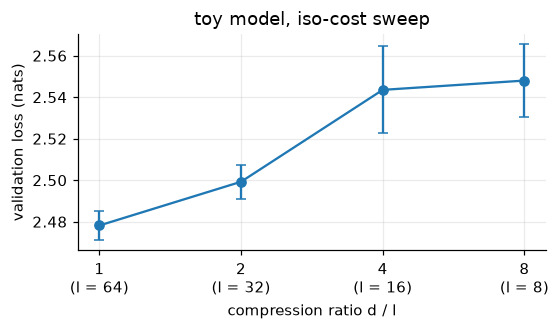

In [10]:
def build_alpha(a, seed):
    torch.manual_seed(seed)
    mk = (lambda: A.MoE(Dm, 8, 2, 32, n_shared=1, f_shared=32)) if a == 1 else (lambda: A.MoE(Dm, 8 * a, 2, 32, latent=Dm // a, n_shared=1, f_shared=32))
    return A.MiniLM(data.vocab, Dm, lambda i: A.Attn(Dm, Hh), lambda i: mk(), n_layers=NL)

alphas = [1, 2, 4, 8]
sweep = {}
t0 = time.time()
for a in alphas:
    v = []
    for s in [0, 1]:
        mdl = build_alpha(a, s)
        A.train_lm(mdl, data, steps=400, B=32, T=64, lr=3e-3, seed=s)
        v.append(A.evaluate(mdl, data))
    sweep[a] = np.array(v)
    print(f"alpha = {a} (latent width {Dm // a:2d}, {8 * a:2d} experts, top-2): val loss {sweep[a].mean():.3f}  seeds {np.round(v, 3)}   ({time.time() - t0:.0f} s)")

# the paper's Figure 4 control: compress by 4 but do NOT scale the number of experts
unscaled = []
for s_ in [0, 1]:
    torch.manual_seed(s_)
    mdl = A.MiniLM(data.vocab, Dm, lambda i: A.Attn(Dm, Hh), lambda i: A.MoE(Dm, 8, 2, 32, latent=Dm // 4, n_shared=1, f_shared=32), n_layers=NL)
    A.train_lm(mdl, data, steps=400, B=32, T=64, lr=3e-3, seed=s_)
    unscaled.append(A.evaluate(mdl, data))
unscaled = np.array(unscaled)
print(f"alpha = 4 with the experts NOT scaled (8 experts, top-2, latent width 16): val loss {unscaled.mean():.3f}  seeds {np.round(unscaled, 3)}")
check("every compressed layer is worse than the uncompressed one by more than 0.015 (no compression level matches it)", all(sweep[a].mean() > sweep[1].mean() + 0.015 for a in [2, 4, 8]))
check("compressing without adding experts is the worst of the alpha = 4 variants", unscaled.mean() > sweep[4].mean())

fig, ax = plt.subplots(figsize=(5.2, 3.1))
ax.errorbar(alphas, [sweep[a].mean() for a in alphas], [sweep[a].std() for a in alphas], marker="o", color=C["blue"], capsize=3)
ax.set_xscale("log", base=2); ax.set_xticks(alphas); ax.set_xticklabels([f"{a}\n(l = {Dm // a})" for a in alphas])
ax.set_xlabel("compression ratio d / l"); ax.set_ylabel("validation loss (nats)"); ax.set_title("toy model, iso-cost sweep"); plt.tight_layout(); plt.show()

**Result (2 seeds; eff configuration; validation loss in nats).** $\alpha=1$: 2.478; $\alpha=2$: 2.499; $\alpha=4$: 2.544; $\alpha=8$: 2.548. Loss rises as the latent shrinks, with most of the damage between $\alpha=1$ and $\alpha=4$ and no further visible change from 4 to 8 (a difference of 0.004, inside the seed noise of 0.02 to 0.03). **No compression level matches the uncompressed layer** in this toy. The control the paper shows in its Figure 4 is the case with the latent width reduced by $4\times$ but the number of experts **not** increased: ours gives 2.575 (seeds 2.564 and 2.585), against 2.544 for the same compression with $4\times$ as many experts. So scaling the experts recovers about 0.03 of the roughly 0.10 that compression costs, in the direction the paper reports (their Figure 4: scaling the expert count "effectively mitigates the accuracy loss caused by compression"), but the recovery here is partial and the two seeds' ranges touch (2.523 to 2.565 against 2.564 to 2.585). What this toy cannot show is the other half of the paper's argument, that the mitigated model then *beats* the uncompressed one when the top-$K$ is scaled as well (section 5: it does not here).

## What this notebook did and did not show

**Shown (checks).** The paper's roofline threshold of about 1,418 tokens per expert is reproduced from its stated hardware numbers. For $\alpha=d/\ell$, the acc variant has exactly the same expert parameters, routed compute and message size as the standard layer, and the eff variant sends $\alpha$ times fewer messages; $\binom{\alpha N}{\alpha K}\ge\binom{N}{K}^{\alpha}$ holds for the examples. Sections 5 and 6 report what training small models under these layouts found, with the interpretation written under each.

**Not shown.** The paper's results are from 16B and 95B mixture-of-experts models and hybrid Mamba-attention models trained on up to over a trillion tokens, measured on downstream accuracies and on projected serving throughput at trillion-parameter scale (their Figures 6 and 7). We have none of that: no downstream task, no hardware timings, no measure of all-to-all traffic, and our "cost" is a parameter and multiply-add count. Our projections are a larger fraction of the layer than in a real model. We did not implement load balancing, so routing results include whatever imbalance the unbalanced router produced; none of our toy models is a test of the paper's accuracy-per-FLOP claim at its scale.

**Next.** Notebook 8 is about that imbalance: quantile balancing, a way of choosing per-expert thresholds so that every expert receives an equal share.

In [11]:
print("passed:", len(PASS), "| failed:", len(FAIL))
assert not FAIL, FAIL

passed: 14 | failed: 0
